# CIDFA++ — End-to-End Crop-Disjoint Plant Disease Detection

**Google Colab notebook (from scratch)**

- **Task:** binary classification: healthy vs diseased leaf images.
- **Source crops for training/validation:** Potato and Tomato.
- **Held-out target crops for final evaluation:** Corn and Pepper.
- **Backbone:** ImageNet-pretrained MobileNetV2.
- **Proposed components:** disease/context feature branches, spatial cross-attention, domain-adversarial training with gradient reversal, and MMD feature alignment.

**Important:** this notebook computes new results when you run it. No accuracy values are assumed or pre-filled. Do not report a result until the run completes successfully. The dataset folder should contain one subfolder per class, e.g. `Tomato___healthy`, `Potato___Early_blight`, `Corn_(maize)___healthy`, etc.

In [2]:
# CELL 1 — Install/import dependencies and check runtime
!pip -q install scikit-learn pandas matplotlib

import os, json, time, random, math, shutil
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    brier_score_loss
)

print('TensorFlow:', tf.__version__)
print('GPUs:', tf.config.list_physical_devices('GPU'))
if tf.config.list_physical_devices('GPU'):
    try:
        for gpu in tf.config.list_physical_devices('GPU'):
            tf.config.experimental.set_memory_growth(gpu, True)
    except Exception as e:
        print('GPU memory growth note:', e)


TensorFlow: 2.21.0
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [3]:
# CELL 2 — Mount Google Drive and set dataset path
from google.colab import drive
drive.mount('/content/drive')

# CHANGE THIS to the directory whose immediate children are class folders.
# Example: /content/drive/MyDrive/PlantVillage
DATASET_DIR = '/content/drive/MyDrive/dataset'

print('Dataset directory:', DATASET_DIR)
if not os.path.isdir(DATASET_DIR):
    raise FileNotFoundError(
        f'Dataset folder not found: {DATASET_DIR}. Edit DATASET_DIR in this cell.'
    )
print('Example class folders:', sorted([p.name for p in Path(DATASET_DIR).iterdir() if p.is_dir()])[:20])


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dataset directory: /content/drive/MyDrive/dataset
Example class folders: ['Corn___Common_rust', 'Corn___Northern_Leaf_Blight', 'Corn___healthy', 'Pepper,_bell___Bacterial_spot', 'Pepper,_bell___healthy', 'Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy', 'Tomato___Early_blight', 'Tomato___Late_blight', 'Tomato___healthy']


In [4]:
# CELL 3 — Reproducibility, configuration, and output folders
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

WORK_DIR = '/content/cidfa_plus_run'
SPLIT_DIR = os.path.join(WORK_DIR, 'splits')
CKPT_DIR = os.path.join(WORK_DIR, 'checkpoints')
FIG_DIR = os.path.join(WORK_DIR, 'figures')
EXP_DIR = os.path.join(WORK_DIR, 'experiments')
for d in [SPLIT_DIR, CKPT_DIR, FIG_DIR, EXP_DIR]:
    os.makedirs(d, exist_ok=True)

IMG_SIZE = 224
BATCH_SIZE = 32
EPOCHS = 20
LR = 1e-4
VAL_FRAC = 0.15
LAMBDA_ALIGN = 0.2
LAMBDA_ADV = 0.1
NUM_CLASSES = 2  # 0 = diseased, 1 = healthy
SOURCE_CROPS = ['Potato', 'Tomato']
TARGET_CROPS = ['Corn', 'Pepper']
AUTOTUNE = tf.data.AUTOTUNE

print('Config ready:', {'img_size': IMG_SIZE, 'batch_size': BATCH_SIZE,
      'epochs': EPOCHS, 'source': SOURCE_CROPS, 'held_out': TARGET_CROPS})


Config ready: {'img_size': 224, 'batch_size': 32, 'epochs': 20, 'source': ['Potato', 'Tomato'], 'held_out': ['Corn', 'Pepper']}


## 1. Build a crop-disjoint split

The script reads image paths from class subfolders. Potato and Tomato are split into train/validation sets; Corn and Pepper are reserved for final target evaluation and are never used for training or model selection. Labels are binary: **0 = diseased, 1 = healthy**. Crop-domain IDs are assigned only to the source crops.

In [7]:
# CELL 4 — Scan image files and create source/target manifests
VALID_EXTS = {'.jpg', '.jpeg', '.png', '.bmp'}

def infer_crop(class_name):
    # PlantVillage names usually use Crop___Disease. Keep crop token intact.
    return class_name.split('___')[0].split(',')[0].strip()

def crop_matches(crop_name, requested_name):
    c, r = crop_name.lower(), requested_name.lower()
    if r == 'corn':
        return c.startswith('corn')  # covers Corn and Corn_(maize)
    if r == 'pepper':
        return c.startswith('pepper')  # covers Pepper and Pepper,_bell
    return c.startswith(r)

records = []
# Using the updated DATASET_DIR (which points to '/content/dataset')
for class_dir in sorted(Path(DATASET_DIR).iterdir()):
    if not class_dir.is_dir():
        continue
    class_name = class_dir.name
    crop_name = infer_crop(class_name)
    source_match = any(crop_matches(crop_name, c) for c in SOURCE_CROPS)
    target_match = any(crop_matches(crop_name, c) for c in TARGET_CROPS)
    if not (source_match or target_match):
        continue
    label = 1 if 'healthy' in class_name.lower() else 0
    split_type = 'source' if source_match else 'target'
    for fp in class_dir.rglob('*'):
        if fp.is_file() and fp.suffix.lower() in VALID_EXTS:
            records.append({
                'path': str(fp), 'class_name': class_name, 'crop': crop_name,
                'label': int(label), 'split_type': split_type
            })

all_df = pd.DataFrame(records)
if all_df.empty:
    raise ValueError('No matching images found. Check DATASET_DIR and class folder names.')
source_df = all_df[all_df.split_type == 'source'].copy()
target_df = all_df[all_df.split_type == 'target'].copy()
if source_df.empty or target_df.empty:
    raise ValueError(f'Need source and target images. Source={len(source_df)}, target={len(target_df)}')

# Stratify by full source class when every class has enough examples; otherwise use binary label.
stratify_values = source_df['class_name']
if stratify_values.value_counts().min() < 2:
    stratify_values = source_df['label']
train_df, val_df = train_test_split(
    source_df, test_size=VAL_FRAC, random_state=SEED, stratify=stratify_values
)

# Assign source crop domain IDs deterministically; only source crop IDs are used in training.
source_crop_names = sorted(train_df['crop'].unique().tolist())
if len(source_crop_names) != 2:
    raise ValueError(f'Expected exactly two source crops {SOURCE_CROPS}; found {source_crop_names}')
crop_to_id = {crop: i for i, crop in enumerate(source_crop_names)}
for frame in (train_df, val_df):
    frame['domain'] = frame['crop'].map(crop_to_id).astype('int32')
target_df['domain'] = -1

train_df.to_csv(os.path.join(SPLIT_DIR, 'train_manifest.csv'), index=False)
val_df.to_csv(os.path.join(SPLIT_DIR, 'val_manifest.csv'), index=False)
target_df.to_csv(os.path.join(SPLIT_DIR, 'test_manifest.csv'), index=False)

print('Images:', len(all_df), '| train:', len(train_df), '| validation:', len(val_df), '| held-out test:', len(target_df))
print('Source classes:', sorted(source_df.class_name.unique()))
print('Train crop counts:', train_df.crop.value_counts().to_dict())
print('Target crop counts:', target_df.crop.value_counts().to_dict())
print('Binary label counts (train):', train_df.label.value_counts().to_dict())
print('Domain IDs:', crop_to_id)
assert set(train_df.crop).isdisjoint(set(target_df.crop)), 'Crop leakage detected!'

Images: 12466 | train: 5654 | validation: 998 | held-out test: 5814
Source classes: ['Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy', 'Tomato___Early_blight', 'Tomato___Late_blight', 'Tomato___healthy']
Train crop counts: {'Tomato': 3825, 'Potato': 1829}
Target crop counts: {'Corn': 3339, 'Pepper': 2475}
Binary label counts (train): {0: 4173, 1: 1481}
Domain IDs: {'Potato': 0, 'Tomato': 1}


In [13]:
# QUICK CHECK: Test if the pipeline can load a single batch quickly
import time
print("Attempting to pull 1 batch from train_ds...")
start_time = time.time()
try:
    for images, labels in train_ds.take(1):
        duration = time.time() - start_time
        print(f"Successfully loaded 1 batch in {duration:.2f} seconds!")
        print("Image batch shape:", images.shape)
        print("Label keys:", list(labels.keys()))
except Exception as e:
    print("An error occurred while reading from your dataset:", e)

Attempting to pull 1 batch from train_ds...
An error occurred while reading from your dataset: name 'train_ds' is not defined


In [14]:
# DIAGNOSTIC CHECK: Test raw file-read speed from Google Drive
import time
import cv2
from PIL import Image

test_path = train_df['path'].iloc[0]
print(f"Testing raw read speed on: {test_path}")

start_time = time.time()
try:
    with open(test_path, 'rb') as f:
        data = f.read()
    print(f"Success! Read {len(data)} bytes in {time.time() - start_time:.4f} seconds.")

    # Try to decode it as an image
    img = Image.open(test_path)
    print(f"Image decoded successfully. Size: {img.size}")
except Exception as e:
    print("Error reading raw image file:", e)

Testing raw read speed on: /content/drive/MyDrive/dataset/Tomato___healthy/image (661).JPG
Success! Read 27276 bytes in 0.0029 seconds.
Image decoded successfully. Size: (256, 256)


In [15]:
# CELL 5 — TensorFlow input pipeline

def load_image(path, label):
    raw = tf.io.read_file(path)
    image = tf.io.decode_image(raw, channels=3, expand_animations=False)
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, [IMG_SIZE, IMG_SIZE])
    image = tf.keras.applications.mobilenet_v2.preprocess_input(image)
    return image, tf.cast(label, tf.int32)

def augment_image(image, label):
    image = tf.image.random_flip_left_right(image, seed=SEED)
    image = tf.image.random_brightness(image, max_delta=0.08, seed=SEED)
    image = tf.clip_by_value(image, -1.0, 1.0)
    return image, label

def make_source_dataset(df, training=False, include_domain=True):
    paths = df['path'].astype(str).values
    labels = df['label'].astype('int32').values
    if include_domain:
        domains = df['domain'].astype('int32').values
        ds = tf.data.Dataset.from_tensor_slices((paths, labels, domains))
        def _load(p, y, d):
            img, y = load_image(p, y)
            return img, {'disease_output': y, 'domain_output': tf.cast(d, tf.int32)}
        ds = ds.map(_load, num_parallel_calls=AUTOTUNE)
        if training:
            ds = ds.map(lambda x, y: (augment_image(x, y['disease_output'])[0], y), num_parallel_calls=AUTOTUNE)
    else:
        ds = tf.data.Dataset.from_tensor_slices((paths, labels))
        ds = ds.map(load_image, num_parallel_calls=AUTOTUNE)
        if training:
            ds = ds.map(augment_image, num_parallel_calls=AUTOTUNE)
    if training:
        ds = ds.shuffle(min(len(df), 5000), seed=SEED, reshuffle_each_iteration=True)
    return ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)

def make_eval_dataset(df):
    ds = tf.data.Dataset.from_tensor_slices((df['path'].astype(str).values,
                                             df['label'].astype('int32').values))
    ds = ds.map(load_image, num_parallel_calls=AUTOTUNE)
    return ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)

train_ds = make_source_dataset(train_df, training=True, include_domain=True)
val_ds = make_source_dataset(val_df, training=False, include_domain=True)
target_ds = make_eval_dataset(target_df)
train_ds_baseline = make_source_dataset(train_df, training=True, include_domain=False)
val_ds_baseline = make_source_dataset(val_df, training=False, include_domain=False)

In [16]:
# Run a test to load 1 batch from the initialized dataset
import time
print("Pulling 1 batch from train_ds to check load speed...")
start = time.time()
for xb, yb in train_ds.take(1):
    print(f"Successfully loaded in {time.time() - start:.2f} seconds!")
    print('Image batch shape:', xb.shape)
    print('Label keys:', list(yb.keys()), {k: v.shape for k, v in yb.items()})

Pulling 1 batch from train_ds to check load speed...
Successfully loaded in 14.23 seconds!
Image batch shape: (32, 224, 224, 3)
Label keys: ['disease_output', 'domain_output'] {'disease_output': TensorShape([32]), 'domain_output': TensorShape([32])}


In [17]:
# CELL 2.1 — Copy dataset to local SSD for ultra-fast training
import os
import shutil

LOCAL_DATASET_DIR = '/content/dataset'

if not os.path.exists(LOCAL_DATASET_DIR):
    print("Copying dataset from Google Drive to fast local SSD storage...")
    shutil.copytree('/content/drive/MyDrive/dataset', LOCAL_DATASET_DIR)
    print("Copy completed successfully!")
else:
    print("Local dataset already exists.")

# Redefine DATASET_DIR to use the local path
DATASET_DIR = LOCAL_DATASET_DIR
print("New DATASET_DIR set to:", DATASET_DIR)

Local dataset already exists.
New DATASET_DIR set to: /content/dataset


## 2. CIDFA++ model

The attention layer below operates on **spatial tokens** from the feature maps rather than a single token. MMD compares source-domain feature distributions when both source crops appear in a batch. Gradient reversal encourages the domain classifier to be unable to infer the source crop from disease features.

In [18]:
# CELL 6 — Custom layers: CBAM, gradient reversal, and spatial cross-attention
class ChannelAttention(layers.Layer):
    def __init__(self, channels, reduction=16, **kwargs):
        super().__init__(**kwargs)
        hidden = max(channels // reduction, 1)
        self.avg_pool = layers.GlobalAveragePooling2D()
        self.max_pool = layers.GlobalMaxPooling2D()
        self.fc1 = layers.Dense(hidden, activation='relu', use_bias=False)
        self.fc2 = layers.Dense(channels, use_bias=False)
    def call(self, x):
        avg = self.fc2(self.fc1(self.avg_pool(x)))
        mx = self.fc2(self.fc1(self.max_pool(x)))
        scale = tf.nn.sigmoid(avg + mx)[:, None, None, :]
        return x * scale

class SpatialAttention(layers.Layer):
    def __init__(self, **kwargs):
        super().__init__(**kwargs)
        self.conv = layers.Conv2D(1, 7, padding='same', activation='sigmoid', use_bias=False)
    def call(self, x):
        avg = tf.reduce_mean(x, axis=-1, keepdims=True)
        mx = tf.reduce_max(x, axis=-1, keepdims=True)
        return x * self.conv(tf.concat([avg, mx], axis=-1))

class CBAM(layers.Layer):
    def __init__(self, channels, reduction=16, **kwargs):
        super().__init__(**kwargs)
        self.ca = ChannelAttention(channels, reduction)
        self.sa = SpatialAttention()
    def call(self, x):
        return self.sa(self.ca(x))

@tf.custom_gradient
def reverse_gradient(x):
    def grad(dy):
        return -dy
    return x, grad

class GradientReversalLayer(layers.Layer):
    def call(self, x):
        return reverse_gradient(x)

class SpatialCrossAttentionAlignment(layers.Layer):
    def __init__(self, channels=256, num_heads=4, **kwargs):
        super().__init__(**kwargs)
        self.channels = channels
        self.num_heads = num_heads
        self.mha = layers.MultiHeadAttention(num_heads=num_heads, key_dim=channels // num_heads)
        self.norm = layers.LayerNormalization(epsilon=1e-6)
        self.pool = layers.GlobalAveragePooling1D()
    def call(self, inputs, training=False):
        disease_map, context_map = inputs
        shape = tf.shape(disease_map)
        # [batch, height*width, channels], so attention sees multiple spatial tokens.
        q = tf.reshape(disease_map, [shape[0], -1, self.channels])
        kv = tf.reshape(context_map, [shape[0], -1, self.channels])
        attended = self.mha(query=q, value=kv, key=kv, training=training)
        attended = self.norm(q + attended)
        return self.pool(attended)

print('Custom layers defined.')


Custom layers defined.


In [19]:
# CELL 7 — MMD loss and full custom training model

def compute_mmd(x, y, bandwidth=1.0):
    x = tf.cast(x, tf.float32)
    y = tf.cast(y, tf.float32)
    x = tf.reshape(x, [tf.shape(x)[0], -1])
    y = tf.reshape(y, [tf.shape(y)[0], -1])
    def kernel(a, b):
        a2 = tf.reduce_sum(tf.square(a), axis=1, keepdims=True)
        b2 = tf.reduce_sum(tf.square(b), axis=1, keepdims=True)
        dist = tf.maximum(a2 - 2.0 * tf.matmul(a, b, transpose_b=True) + tf.transpose(b2), 0.0)
        return tf.exp(-dist / (2.0 * bandwidth ** 2))
    return tf.reduce_mean(kernel(x, x)) + tf.reduce_mean(kernel(y, y)) - 2.0 * tf.reduce_mean(kernel(x, y))

class IntegratedCIDFAWithMMD(keras.Model):
    def __init__(self, backbone, lambda_align=0.2, lambda_adv=0.1, **kwargs):
        super().__init__(**kwargs)
        self.backbone = backbone
        self.backbone.trainable = False  # fine-tuning can be a separate experiment
        self.lambda_align = float(lambda_align)
        self.lambda_adv = float(lambda_adv)

        self.disease_proj = layers.Conv2D(256, 1, padding='same', use_bias=False)
        self.disease_bn = layers.BatchNormalization()
        self.disease_cbam = CBAM(256)
        self.context_proj = layers.Conv2D(256, 1, padding='same', use_bias=False)
        self.context_bn = layers.BatchNormalization()
        self.context_cbam = CBAM(256)
        self.cross_attention = SpatialCrossAttentionAlignment(256, 4)
        self.disease_pool = layers.GlobalAveragePooling2D()
        self.grl = GradientReversalLayer()
        self.domain_hidden = layers.Dense(128, activation='relu')
        self.domain_classifier = layers.Dense(2, activation='softmax', name='domain_output')
        self.gate = layers.Dense(256, activation='sigmoid')
        self.dropout = layers.Dropout(0.4)
        self.disease_classifier = layers.Dense(2, activation='softmax', name='disease_output')

        self.ce = keras.losses.SparseCategoricalCrossentropy()
        self.loss_tracker = keras.metrics.Mean(name='loss')
        self.cls_tracker = keras.metrics.Mean(name='cls_loss')
        self.align_tracker = keras.metrics.Mean(name='mmd_loss')
        self.adv_tracker = keras.metrics.Mean(name='domain_loss')
        self.acc_tracker = keras.metrics.SparseCategoricalAccuracy(name='disease_accuracy')

    @property
    def metrics(self):
        return [self.loss_tracker, self.cls_tracker, self.align_tracker, self.adv_tracker, self.acc_tracker]

    def call(self, images, training=False):
        base = self.backbone(images, training=False)
        fd = tf.nn.relu(self.disease_bn(self.disease_proj(base), training=training))
        fc = tf.nn.relu(self.context_bn(self.context_proj(base), training=training))
        fd = self.disease_cbam(fd)
        fc = self.context_cbam(fc)
        disease_vector = self.disease_pool(fd)
        context_vector = self.cross_attention([fd, fc], training=training)
        gate = self.gate(tf.concat([disease_vector, context_vector], axis=-1))
        fused = gate * disease_vector + (1.0 - gate) * context_vector
        disease_probs = self.disease_classifier(self.dropout(fused, training=training))
        domain_probs = self.domain_classifier(self.domain_hidden(self.grl(disease_vector)))
        return disease_probs, domain_probs, disease_vector

    def _losses_for_batch(self, labels, disease_probs, domain_probs, features):
        y = tf.cast(tf.reshape(labels['disease_output'], [-1]), tf.int32)
        domain = tf.cast(tf.reshape(labels['domain_output'], [-1]), tf.int32)
        cls_loss = tf.reduce_mean(self.ce(y, disease_probs))
        adv_loss = tf.reduce_mean(self.ce(domain, domain_probs))
        f0 = tf.boolean_mask(features, tf.equal(domain, 0))
        f1 = tf.boolean_mask(features, tf.equal(domain, 1))
        align_loss = tf.cond(
            tf.logical_and(tf.shape(f0)[0] > 0, tf.shape(f1)[0] > 0),
            lambda: compute_mmd(f0, f1),
            lambda: tf.constant(0.0, tf.float32)
        )
        total = cls_loss + self.lambda_adv * adv_loss + self.lambda_align * align_loss
        if self.losses:
            total += tf.add_n(self.losses)
        return total, cls_loss, align_loss, adv_loss, y

    def train_step(self, data):
        images, labels = data
        with tf.GradientTape() as tape:
            disease_probs, domain_probs, features = self(images, training=True)
            total, cls, align, adv, y = self._losses_for_batch(labels, disease_probs, domain_probs, features)
        grads = tape.gradient(total, self.trainable_variables)
        pairs = [(g, v) for g, v in zip(grads, self.trainable_variables) if g is not None]
        self.optimizer.apply_gradients(pairs)
        self.loss_tracker.update_state(total)
        self.cls_tracker.update_state(cls)
        self.align_tracker.update_state(align)
        self.adv_tracker.update_state(adv)
        self.acc_tracker.update_state(y, disease_probs)
        return {m.name: m.result() for m in self.metrics}

    def test_step(self, data):
        images, labels = data
        disease_probs, domain_probs, features = self(images, training=False)
        total, cls, align, adv, y = self._losses_for_batch(labels, disease_probs, domain_probs, features)
        self.loss_tracker.update_state(total)
        self.cls_tracker.update_state(cls)
        self.align_tracker.update_state(align)
        self.adv_tracker.update_state(adv)
        self.acc_tracker.update_state(y, disease_probs)
        return {m.name: m.result() for m in self.metrics}

# Build backbone and CIDFA++ model
backbone = keras.applications.MobileNetV2(
    input_shape=(IMG_SIZE, IMG_SIZE, 3), include_top=False, weights='imagenet'
)
backbone.trainable = False
cidfa = IntegratedCIDFAWithMMD(backbone, lambda_align=LAMBDA_ALIGN, lambda_adv=LAMBDA_ADV, name='CIDFA_Plus_MMD')

# Build once to create weights
_ = cidfa(tf.zeros([1, IMG_SIZE, IMG_SIZE, 3]), training=False)
cidfa.compile(optimizer=keras.optimizers.Adam(learning_rate=LR))
cidfa.summary()


Model: "CIDFA_Plus_MMD"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (1, 7, 7, 256)         │       327,680 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (1, 7, 7, 256)         │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ cbam_2 (CBAM)                   │ ?                      │         8,290 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (1, 7, 7, 256)         │       327,680 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (1, 7, 7, 256)         │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ cbam_3 (CBAM)                   │ ?                      │         8,290 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_cross_attention_alignm… │ ?                      │       263,680 │
│ (SpatialCrossAttentionAlignmen… │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_5      │ ?                      │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gradient_reversal_layer_1       │ ?                      │             0 │
│ (GradientReversalLayer)         │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (1, 128)               │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ domain_output (Dense)           │ (1, 2)                 │           258 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (1, 256)               │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ disease_output (Dense)          │ (1, 2)                 │           514 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,360,648 (12.82 MB)

 Trainable params: 1,101,640 (4.20 MB)

 Non-trainable params: 2,259,008 (8.62 MB)

In [20]:
# CELL 8 — Train CIDFA++ and save best checkpoint
import os
import json

CIDFA_CKPT = os.path.join(CKPT_DIR, 'best_cidfa_plus.weights.h5')
cidfa_callbacks = [
    keras.callbacks.ModelCheckpoint(
        CIDFA_CKPT, monitor='val_disease_accuracy', mode='max',
        save_best_only=True, save_weights_only=True, verbose=1
    ),
    keras.callbacks.EarlyStopping(
        monitor='val_disease_accuracy', mode='max', patience=5,
        restore_best_weights=True, verbose=1
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss', factor=0.5, patience=2, min_lr=1e-6, verbose=1
    ),
    keras.callbacks.CSVLogger(os.path.join(EXP_DIR, 'cidfa_training_log.csv'))
]

history_cidfa = cidfa.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=cidfa_callbacks,
    verbose=1
)
# ModelCheckpoint already saves best weights; restore them explicitly for evaluation.
cidfa.load_weights(CIDFA_CKPT)
with open(os.path.join(EXP_DIR, 'cidfa_history.json'), 'w') as f:
    json.dump({k: [float(v) for v in vals] for k, vals in history_cidfa.history.items()}, f, indent=2)
print('Best checkpoint:', CIDFA_CKPT)

Epoch 1/20
177/177 ━━━━━━━━━━━━━━━━━━━━ 0s 146ms/step - cls_loss: 0.2699 - disease_accuracy: 0.8753 - domain_loss: 0.6316 - loss: 0.3725 - mmd_loss: 0.1973
Epoch 1: val_disease_accuracy improved from None to 0.97996, saving model to /content/cidfa_plus_run/checkpoints/best_cidfa_plus.weights.h5

Epoch 1: finished saving model to /content/cidfa_plus_run/checkpoints/best_cidfa_plus.weights.h5
177/177 ━━━━━━━━━━━━━━━━━━━━ 81s 242ms/step - cls_loss: 0.1268 - disease_accuracy: 0.9491 - domain_loss: 0.6141 - loss: 0.2244 - mmd_loss: 0.1811 - val_cls_loss: 0.0557 - val_disease_accuracy: 0.9800 - val_domain_loss: 0.6299 - val_loss: 0.1479 - val_mmd_loss: 0.1460 - learning_rate: 1.0000e-04
Epoch 2/20
177/177 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step - cls_loss: 0.0356 - disease_accuracy: 0.9877 - domain_loss: 0.6409 - loss: 0.1279 - mmd_loss: 0.1408
Epoch 2: val_disease_accuracy improved from 0.97996 to 0.98196, saving model to /content/cidfa_plus_run/checkpoints/best_cidfa_plus.weights.h5

Epoch 2: fi

## 3. Train a fair MobileNetV2 baseline

The baseline uses the same source train/validation split, preprocessing, binary labels, and held-out target test set. It does not use MMD, domain adversarial learning, or cross-attention.

In [21]:
# CELL 9 — Build and train baseline MobileNetV2
base_input = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3), name='image')
base_backbone = keras.applications.MobileNetV2(
    input_shape=(IMG_SIZE, IMG_SIZE, 3), include_top=False, weights='imagenet'
)
base_backbone.trainable = False
z = base_backbone(base_input, training=False)
z = layers.GlobalAveragePooling2D()(z)
z = layers.Dropout(0.4)(z)
base_output = layers.Dense(2, activation='softmax', name='disease_output')(z)
baseline = keras.Model(base_input, base_output, name='MobileNetV2_Baseline')
baseline.compile(
    optimizer=keras.optimizers.Adam(learning_rate=LR),
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=[keras.metrics.SparseCategoricalAccuracy(name='accuracy')]
)
BASE_CKPT = os.path.join(CKPT_DIR, 'best_mobilenetv2_baseline.weights.h5')
base_callbacks = [
    keras.callbacks.ModelCheckpoint(BASE_CKPT, monitor='val_accuracy', mode='max',
                                    save_best_only=True, save_weights_only=True, verbose=1),
    keras.callbacks.EarlyStopping(monitor='val_accuracy', mode='max', patience=5,
                                  restore_best_weights=True, verbose=1),
    keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2,
                                      min_lr=1e-6, verbose=1),
    keras.callbacks.CSVLogger(os.path.join(EXP_DIR, 'baseline_training_log.csv'))
]
history_baseline = baseline.fit(
    train_ds_baseline, validation_data=val_ds_baseline,
    epochs=EPOCHS, callbacks=base_callbacks, verbose=1
)
baseline.load_weights(BASE_CKPT)
with open(os.path.join(EXP_DIR, 'baseline_history.json'), 'w') as f:
    json.dump({k: [float(v) for v in vals] for k, vals in history_baseline.history.items()}, f, indent=2)
print('Baseline checkpoint:', BASE_CKPT)


Epoch 1/20
177/177 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step - accuracy: 0.6627 - loss: 0.6764
Epoch 1: val_accuracy improved from None to 0.91683, saving model to /content/cidfa_plus_run/checkpoints/best_mobilenetv2_baseline.weights.h5

Epoch 1: finished saving model to /content/cidfa_plus_run/checkpoints/best_mobilenetv2_baseline.weights.h5
177/177 ━━━━━━━━━━━━━━━━━━━━ 35s 105ms/step - accuracy: 0.7471 - loss: 0.5323 - val_accuracy: 0.9168 - val_loss: 0.2526 - learning_rate: 1.0000e-04
Epoch 2/20
177/177 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - accuracy: 0.8731 - loss: 0.2991
Epoch 2: val_accuracy improved from 0.91683 to 0.96794, saving model to /content/cidfa_plus_run/checkpoints/best_mobilenetv2_baseline.weights.h5

Epoch 2: finished saving model to /content/cidfa_plus_run/checkpoints/best_mobilenetv2_baseline.weights.h5
177/177 ━━━━━━━━━━━━━━━━━━━━ 18s 50ms/step - accuracy: 0.8916 - loss: 0.2706 - val_accuracy: 0.9679 - val_loss: 0.1486 - learning_rate: 1.0000e-04
Epoch 3/20
177/177 ━━━━━━━━━

In [22]:
# CELL 10 — Evaluation helpers

def collect_predictions(model, dataset, cidfa_model=False):
    y_true, probs = [], []
    for batch in dataset:
        images, labels = batch
        if cidfa_model:
            p, _, _ = model(images, training=False)
        else:
            p = model(images, training=False)
        y_true.extend(labels.numpy().astype(int).tolist())
        probs.extend(p.numpy().tolist())
    return np.asarray(y_true, dtype=int), np.asarray(probs, dtype=float)

def expected_calibration_error(y_true, probs, n_bins=15):
    pred = probs.argmax(axis=1)
    conf = probs.max(axis=1)
    correct = (pred == y_true).astype(float)
    edges = np.linspace(0.0, 1.0, n_bins + 1)
    ece = 0.0
    for i in range(n_bins):
        mask = (conf > edges[i]) & (conf <= edges[i + 1])
        if mask.any():
            ece += mask.mean() * abs(correct[mask].mean() - conf[mask].mean())
    return float(ece)

def compute_metrics(y_true, probs):
    preds = probs.argmax(axis=1)
    return {
        'accuracy': float(accuracy_score(y_true, preds)),
        'macro_f1': float(f1_score(y_true, preds, average='macro', zero_division=0)),
        'macro_precision': float(precision_score(y_true, preds, average='macro', zero_division=0)),
        'macro_recall': float(recall_score(y_true, preds, average='macro', zero_division=0)),
        'ece': expected_calibration_error(y_true, probs),
        'brier_score': float(np.mean(np.sum((probs - np.eye(2)[y_true])**2, axis=1)))
    }

# Source validation metrics; validation dataset order matches val_df.
val_ds_eval = make_eval_dataset(val_df)
y_val, p_val_cidfa = collect_predictions(cidfa, val_ds_eval, cidfa_model=True)
y_val_b, p_val_base = collect_predictions(baseline, val_ds_eval, cidfa_model=False)

# Held-out target predictions. Target rows are kept in manifest order (no shuffle).
y_test, p_test_cidfa = collect_predictions(cidfa, target_ds, cidfa_model=True)
y_test_b, p_test_base = collect_predictions(baseline, target_ds, cidfa_model=False)
assert np.array_equal(y_test, y_test_b), 'Model evaluation labels do not align.'
assert len(y_test) == len(target_df), 'Prediction count does not match target manifest.'

pred_cidfa = p_test_cidfa.argmax(axis=1)
pred_base = p_test_base.argmax(axis=1)
crops = target_df['crop'].to_numpy()

print('Target set size:', len(y_test))
print('Target crop counts:', pd.Series(crops).value_counts().to_dict())
print('Labels: 0=diseased, 1=healthy')


Target set size: 5814
Target crop counts: {'Corn': 3339, 'Pepper': 2475}
Labels: 0=diseased, 1=healthy


In [23]:
# CELL 11 — Aggregate and per-crop metrics, confusion matrices, reports

def per_crop_metrics(y, probs, crop_array):
    rows = []
    for crop in sorted(np.unique(crop_array)):
        mask = crop_array == crop
        m = compute_metrics(y[mask], probs[mask])
        rows.append({'crop': crop, 'n': int(mask.sum()), **m})
    return pd.DataFrame(rows)

cidfa_target_metrics = compute_metrics(y_test, p_test_cidfa)
base_target_metrics = compute_metrics(y_test, p_test_base)
cidfa_crop_metrics = per_crop_metrics(y_test, p_test_cidfa, crops)
base_crop_metrics = per_crop_metrics(y_test, p_test_base, crops)

# Cross-Crop Generalization Gap uses the best source validation accuracy minus target accuracy.
cidfa_source_val_acc = float(accuracy_score(y_val, p_val_cidfa.argmax(axis=1)))
base_source_val_acc = float(accuracy_score(y_val_b, p_val_base.argmax(axis=1)))
cidfa_ccgg_pp = (cidfa_source_val_acc - cidfa_target_metrics['accuracy']) * 100
base_ccgg_pp = (base_source_val_acc - base_target_metrics['accuracy']) * 100

summary = pd.DataFrame([
    {'model': 'MobileNetV2 baseline', 'source_val_accuracy': base_source_val_acc,
     **base_target_metrics, 'CCGG_percentage_points': base_ccgg_pp},
    {'model': 'CIDFA++ (MMD + GRL + spatial attention)', 'source_val_accuracy': cidfa_source_val_acc,
     **cidfa_target_metrics, 'CCGG_percentage_points': cidfa_ccgg_pp}
])
print('\nOVERALL HELD-OUT RESULTS')
display(summary)
print('\nCIDFA++ by crop')
display(cidfa_crop_metrics)
print('\nBaseline by crop')
display(base_crop_metrics)

print('\nCIDFA++ classification report (0=diseased, 1=healthy)')
print(classification_report(y_test, pred_cidfa, labels=[0,1], target_names=['diseased','healthy'], zero_division=0))
print('Baseline classification report')
print(classification_report(y_test, pred_base, labels=[0,1], target_names=['diseased','healthy'], zero_division=0))

cidfa_crop_metrics.to_csv(os.path.join(EXP_DIR, 'cidfa_per_crop_metrics.csv'), index=False)
base_crop_metrics.to_csv(os.path.join(EXP_DIR, 'baseline_per_crop_metrics.csv'), index=False)
summary.to_csv(os.path.join(EXP_DIR, 'model_comparison.csv'), index=False)



OVERALL HELD-OUT RESULTS


,model,source_val_accuracy,accuracy,macro_f1,macro_precision,macro_recall,ece,brier_score,CCGG_percentage_points
0,MobileNetV2 baseline,0.985972,0.611455,0.502688,0.752026,0.573338,0.313100,0.641532,37.451684
1,CIDFA++ (MMD + GRL + spatial attention),0.988978,0.797214,0.782189,0.841457,0.779668,0.146874,0.339930,19.176433



CIDFA++ by crop


,crop,n,accuracy,macro_f1,macro_precision,macro_recall,ece,brier_score
0,Corn,3339,0.869721,0.845329,0.888612,0.825261,0.080007,0.209173
1,Pepper,2475,0.699394,0.697398,0.768199,0.743249,0.237494,0.516333



Baseline by crop


,crop,n,accuracy,macro_f1,macro_precision,macro_recall,ece,brier_score
0,Corn,3339,0.652890,0.397460,0.826289,0.501291,0.332176,0.659026
1,Pepper,2475,0.555556,0.532907,0.696342,0.621837,0.287364,0.617930



CIDFA++ classification report (0=diseased, 1=healthy)
              precision    recall  f1-score   support

    diseased       0.74      0.97      0.84      3174
     healthy       0.94      0.59      0.72      2640

    accuracy                           0.80      5814
   macro avg       0.84      0.78      0.78      5814
weighted avg       0.83      0.80      0.79      5814

Baseline classification report
              precision    recall  f1-score   support

    diseased       0.59      0.99      0.74      3174
     healthy       0.92      0.16      0.27      2640

    accuracy                           0.61      5814
   macro avg       0.75      0.57      0.50      5814
weighted avg       0.74      0.61      0.52      5814



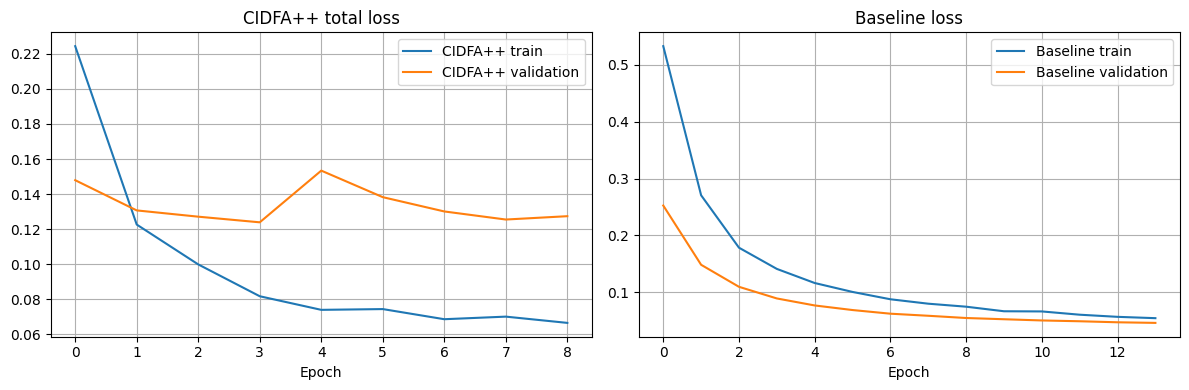

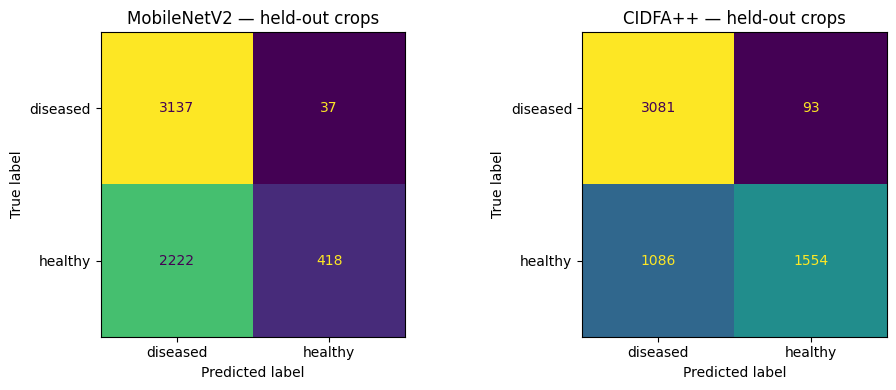

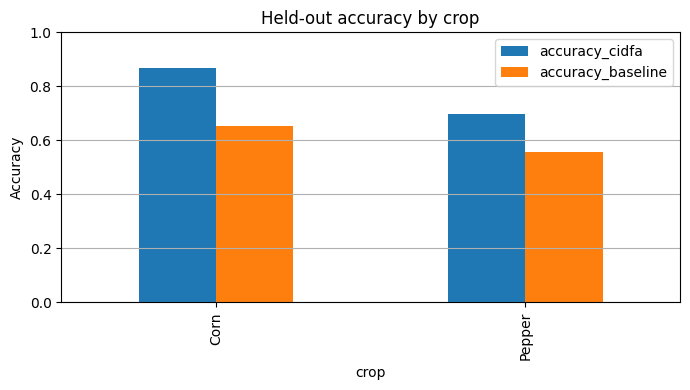

In [24]:
# CELL 12 — Figures: training curves and target confusion matrices
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history_cidfa.history.get('loss', []), label='CIDFA++ train')
axes[0].plot(history_cidfa.history.get('val_loss', []), label='CIDFA++ validation')
axes[0].set_title('CIDFA++ total loss'); axes[0].set_xlabel('Epoch'); axes[0].legend(); axes[0].grid(True)
axes[1].plot(history_baseline.history.get('loss', []), label='Baseline train')
axes[1].plot(history_baseline.history.get('val_loss', []), label='Baseline validation')
axes[1].set_title('Baseline loss'); axes[1].set_xlabel('Epoch'); axes[1].legend(); axes[1].grid(True)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'training_loss_curves.png'), dpi=180, bbox_inches='tight')
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred_base, labels=[0,1], normalize=None),
                       display_labels=['diseased','healthy']).plot(ax=axes[0], colorbar=False)
axes[0].set_title('MobileNetV2 — held-out crops')
ConfusionMatrixDisplay(confusion_matrix(y_test, pred_cidfa, labels=[0,1], normalize=None),
                       display_labels=['diseased','healthy']).plot(ax=axes[1], colorbar=False)
axes[1].set_title('CIDFA++ — held-out crops')
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'target_confusion_matrices.png'), dpi=180, bbox_inches='tight')
plt.show()

# Per-crop accuracy chart
chart_df = cidfa_crop_metrics[['crop','accuracy']].merge(
    base_crop_metrics[['crop','accuracy']], on='crop', suffixes=('_cidfa','_baseline'))
ax = chart_df.set_index('crop').plot(kind='bar', figsize=(7,4))
ax.set_ylabel('Accuracy'); ax.set_ylim(0,1); ax.set_title('Held-out accuracy by crop'); ax.grid(axis='y')
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'per_crop_accuracy.png'), dpi=180, bbox_inches='tight')
plt.show()


In [25]:
# CELL 13 — Measure inference latency correctly (warm-up + repeated runs)
# This measures batch latency on the current runtime. It is not a per-image latency unless divided by batch size.
def measure_batch_latency(model, images, cidfa_model=False, warmup=10, runs=50):
    for _ in range(warmup):
        _ = model(images, training=False)  # warm-up
    # Synchronize pending GPU work by materializing output values.
    _ = model(images, training=False)
    start = time.perf_counter()
    for _ in range(runs):
        out = model(images, training=False)
        if cidfa_model:
            out[0].numpy()
        else:
            out.numpy()
    elapsed = time.perf_counter() - start
    return elapsed * 1000 / runs

sample_images = next(iter(target_ds))[0]
cidfa_latency_ms_batch = measure_batch_latency(cidfa, sample_images, cidfa_model=True)
base_latency_ms_batch = measure_batch_latency(baseline, sample_images, cidfa_model=False)
print(f'CIDFA++ measured latency: {cidfa_latency_ms_batch:.2f} ms/batch ({sample_images.shape[0]} images)')
print(f'Baseline measured latency: {base_latency_ms_batch:.2f} ms/batch ({sample_images.shape[0]} images)')
print('Latency depends on the runtime/GPU, batch size, warm-up, and TensorFlow version.')


CIDFA++ measured latency: 196.70 ms/batch (32 images)
Baseline measured latency: 158.74 ms/batch (32 images)
Latency depends on the runtime/GPU, batch size, warm-up, and TensorFlow version.


In [26]:
# CELL 14 — Save predictions and reproducibility metadata
predictions_df = target_df[['path','class_name','crop','label']].copy()
predictions_df['cidfa_prediction'] = pred_cidfa
predictions_df['cidfa_prob_diseased'] = p_test_cidfa[:,0]
predictions_df['cidfa_prob_healthy'] = p_test_cidfa[:,1]
predictions_df['baseline_prediction'] = pred_base
predictions_df['baseline_prob_diseased'] = p_test_base[:,0]
predictions_df['baseline_prob_healthy'] = p_test_base[:,1]
predictions_df.to_csv(os.path.join(EXP_DIR, 'heldout_predictions.csv'), index=False)

results = {
    'task': 'binary healthy-vs-diseased leaf classification',
    'labels': {'0': 'diseased', '1': 'healthy'},
    'source_crops': SOURCE_CROPS,
    'held_out_target_crops': TARGET_CROPS,
    'seed': SEED,
    'image_size': IMG_SIZE,
    'batch_size': BATCH_SIZE,
    'configured_epochs': EPOCHS,
    'cidfa_epochs_completed': len(history_cidfa.history.get('loss', [])),
    'baseline_epochs_completed': len(history_baseline.history.get('loss', [])),
    'cidfa_source_validation_accuracy': cidfa_source_val_acc,
    'baseline_source_validation_accuracy': base_source_val_acc,
    'cidfa_target': cidfa_target_metrics,
    'baseline_target': base_target_metrics,
    'cidfa_ccgg_percentage_points': cidfa_ccgg_pp,
    'baseline_ccgg_percentage_points': base_ccgg_pp,
    'cidfa_per_crop': cidfa_crop_metrics.to_dict(orient='records'),
    'baseline_per_crop': base_crop_metrics.to_dict(orient='records'),
    'cidfa_latency_ms_per_batch': float(cidfa_latency_ms_batch),
    'baseline_latency_ms_per_batch': float(base_latency_ms_batch),
    'n_train': int(len(train_df)), 'n_validation': int(len(val_df)), 'n_heldout_test': int(len(target_df)),
    'crop_domain_ids': crop_to_id,
    'checkpoint_files': {'cidfa': CIDFA_CKPT, 'baseline': BASE_CKPT}
}
with open(os.path.join(EXP_DIR, 'final_results.json'), 'w') as f:
    json.dump(results, f, indent=2)
print(json.dumps(results, indent=2))


{
  "task": "binary healthy-vs-diseased leaf classification",
  "labels": {
    "0": "diseased",
    "1": "healthy"
  },
  "source_crops": [
    "Potato",
    "Tomato"
  ],
  "held_out_target_crops": [
    "Corn",
    "Pepper"
  ],
  "seed": 42,
  "image_size": 224,
  "batch_size": 32,
  "configured_epochs": 20,
  "cidfa_epochs_completed": 9,
  "baseline_epochs_completed": 14,
  "cidfa_source_validation_accuracy": 0.9889779559118237,
  "baseline_source_validation_accuracy": 0.9859719438877755,
  "cidfa_target": {
    "accuracy": 0.7972136222910217,
    "macro_f1": 0.7821888415085609,
    "macro_precision": 0.8414572735820478,
    "macro_recall": 0.7796678982643066,
    "ece": 0.14687412199098132,
    "brier_score": 0.33993021109332616
  },
  "baseline_target": {
    "accuracy": 0.6114551083591331,
    "macro_f1": 0.5026880909183333,
    "macro_precision": 0.7520258618038054,
    "macro_recall": 0.5733380592312539,
    "ece": 0.3130998097624121,
    "brier_score": 0.6415316988748733
  }

In [27]:
# CELL 15 — Package all outputs and copy to Google Drive
OUTPUT_ZIP = shutil.make_archive('/content/cidfa_plus_results', 'zip', WORK_DIR)
print('Created:', OUTPUT_ZIP)

# Optional persistence folder in Drive
DRIVE_OUTPUT_DIR = '/content/drive/MyDrive/cidfa_plus_results'
os.makedirs(DRIVE_OUTPUT_DIR, exist_ok=True)
shutil.copy2(OUTPUT_ZIP, os.path.join(DRIVE_OUTPUT_DIR, 'cidfa_plus_results.zip'))
print('Copied results ZIP to:', os.path.join(DRIVE_OUTPUT_DIR, 'cidfa_plus_results.zip'))
print('Includes manifests, checkpoints, figures, logs, predictions, and JSON metrics.')


Created: /content/cidfa_plus_results.zip
Copied results ZIP to: /content/drive/MyDrive/cidfa_plus_results/cidfa_plus_results.zip
Includes manifests, checkpoints, figures, logs, predictions, and JSON metrics.


## Before using results in a paper

- Confirm that the held-out crop manifests contain only Corn and Pepper and that neither crop appears in training/validation.
- Review per-class recall and confusion matrices; accuracy alone can hide severe class imbalance.
- Keep baseline and CIDFA++ test predictions from this same run.
- Report measured latency with the hardware, batch size, and runtime configuration.
- Run multiple random seeds if you want robust statistical comparisons.
- This notebook implements a research proposal, not a guarantee of improved performance. MMD compares feature distributions across source crops; because the target crops are held out, target evaluation remains strictly post-training.